# 4. Kiértékelés, hipotézisek és tesztek

1. A hibamérők egy modellre, kézzel újraszámolva.
2. Egy Giacomini–White-teszt kézzel (HAR L1 → L2), összevetve a projekt eredményével.
3. Az öt hipotézis döntése, a fő hatások, az MCS és a kritikus időszakok.
4. Az ábrák.
5. A projekt automatikus tesztjei (21 db).

A notebook csak olvas: semmit nem számol újra a `results/` mappában.

In [1]:
# A projekt gyökerének megkeresése és a közös motor (src/) betöltése
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
print("projekt:", ROOT)

projekt: C:\Users\Tamás\Thesis_V3


In [2]:
from config import FIGURES, TABLES, model_dir

metrics = pd.read_csv(TABLES / "metrics_all.csv")
full = metrics[metrics["sample"] == "full"]
print(f"modellek: {len(full)}, kiértékelési napok: {full['n'].iloc[0]}")
print("A 10 legjobb modell a teljes mintán (QLIKE, kisebb = jobb):")
full.sort_values("QLIKE").head(10)

modellek: 256, kiértékelési napok: 1841
A 10 legjobb modell a teljes mintán (QLIKE, kisebb = jobb):


,family,level,transformation,window,frequency,measure,sample,n,QLIKE,MSE,R2_OOS
535,HAR,L4,Log,3Y,Weekly,Garman_Klass,full,1841,0.024461,0.000271,0.104161
530,HAR,L4,Log,3Y,Weekly,Parkinson,full,1841,0.024510,0.000270,0.112456
375,HAR,L3,Log,3Y,Weekly,Garman_Klass,full,1841,0.024649,0.000272,0.101481
215,HAR,L2,Log,3Y,Weekly,Garman_Klass,full,1841,0.024660,0.000273,0.097707
555,HAR,L4,Log,3Y,Monthly,Garman_Klass,full,1841,0.024691,0.000275,0.093289
1175,LSTM,L4,Log,3Y,Weekly,Garman_Klass,full,1841,0.024698,0.000272,0.101883
370,HAR,L3,Log,3Y,Weekly,Parkinson,full,1841,0.024716,0.000271,0.109530
210,HAR,L2,Log,3Y,Weekly,Parkinson,full,1841,0.024735,0.000273,0.105399
1170,LSTM,L4,Log,3Y,Weekly,Parkinson,full,1841,0.024742,0.000271,0.110270
550,HAR,L4,Log,3Y,Monthly,Parkinson,full,1841,0.024743,0.000274,0.101793


## 1. Hibamérők kézzel egy modellre

In [3]:
MODELL = ("HAR", "L4", "Log", "3Y", "Weekly", "Garman_Klass")      # (család, lépcső, transzf., ablak, gyakoriság, mérték)
BENCHMARK = ("HAR", "L1") + MODELL[2:]                             # az R²_OOS viszonyítási alapja

def betolt(kulcs):
    f = pd.read_csv(model_dir(*kulcs) / "forecasts.csv", index_col="date", parse_dates=True)
    return f[f.index >= "2018-08-30"]                              # a közös kiértékelési időszak

m, b = betolt(MODELL), betolt(BENCHMARK)
a = m["sigma_true"] / m["sigma_hat"]
kezzel = {"QLIKE": np.mean(a - np.log(a) - 1),
          "MSE": np.mean((m["sigma_true"] - m["sigma_hat"]) ** 2)}
kezzel["R2_OOS"] = 1 - kezzel["MSE"] / np.mean((b["sigma_true"] - b["sigma_hat"]) ** 2)
sor = full.set_index(["family", "level", "transformation", "window", "frequency", "measure"]).loc[MODELL]
pd.DataFrame({"kézzel": kezzel, "metrics_all.csv": sor[["QLIKE", "MSE", "R2_OOS"]]})

,kézzel,metrics_all.csv
QLIKE,0.024461,0.024461
MSE,0.000271,0.000271
R2_OOS,0.104161,0.104161


## 2. Giacomini–White-teszt kézzel

d<sub>t</sub> = QLIKE<sub>t</sub>(alap) − QLIKE<sub>t</sub>(bővebb). A t-statisztika = átlag(d) / √(Newey–West-variancia), egyoldalú p-érték.
Ha p < 0,05, a bővebb modell szignifikánsan jobb.

In [4]:
from scipy.stats import norm

ALAP = ("HAR", "L1", "Log", "3Y", "Weekly", "RV")
BOVEBB = ("HAR", "L2", "Log", "3Y", "Weekly", "RV")

def qlike_sor(kulcs):
    f = betolt(kulcs)
    a = f["sigma_true"] / f["sigma_hat"]
    return (a - np.log(a) - 1).to_numpy()

d = qlike_sor(ALAP) - qlike_sor(BOVEBB)
T = len(d)
L = int(np.floor(4 * (T / 100) ** (2 / 9)))                       # Newey–West késleltetés
dc = d - d.mean()
v = dc @ dc / T + sum(2 * (1 - k / (L + 1)) * (dc[k:] @ dc[:-k]) / T for k in range(1, L + 1))
t = d.mean() / np.sqrt(v / T)
p = 1 - norm.cdf(t)

pairs = pd.read_csv(TABLES / "hypothesis_pairs.csv")
proj = pairs[(pairs["base"] == "|".join(ALAP)) & (pairs["test"] == "|".join(BOVEBB)) & (pairs["sample"] == "full")].iloc[0]
print(f"QLIKE-arány (bővebb/alap): {qlike_sor(BOVEBB).mean() / qlike_sor(ALAP).mean():.3f}")
pd.DataFrame({"kézzel": [d.mean(), t, p], "hypothesis_pairs.csv": proj[["mean_diff", "t", "p_one_sided"]].to_numpy()},
             index=["átlag(d)", "t", "p (egyoldalú)"])

QLIKE-arány (bővebb/alap): 0.868


,kézzel,hypothesis_pairs.csv
átlag(d),0.003838,0.003838
t,2.948754,2.948754
p (egyoldalú),0.001595,0.001595


## 3. A hipotézisek döntése

A döntési szabályok előre rögzítettek (`docs/08_kutatasi_kerdesek_hipotezisek.md`); a számokat a `scripts/06_evaluate.py` állítja elő.

In [5]:
hyp = pd.read_csv(TABLES / "hypotheses.csv")
hyp[hyp["sample"] == "full"].set_index("H").T.dropna(how="all")

H,H1,H2,H3,H4,H5
mean_ratio_meas_vs_RV,0.973366,NaN,NaN,NaN,NaN
share_not_sig_worse,1.0,NaN,NaN,NaN,NaN
n_pairs,128.0,32.0,32.0,32.0,NaN
supported,True,True,True,False,False
share_of_total_gain_from_L2,NaN,0.990453,NaN,NaN,NaN
share_L1L2_sig,NaN,1.0,NaN,NaN,NaN
share_L1_lstm_sig_better,NaN,NaN,0.0,NaN,NaN
ratio_L1,NaN,NaN,1.01055,NaN,NaN
ratio_L4,NaN,NaN,1.007844,NaN,NaN
share_HAR_sig,NaN,NaN,NaN,0.0625,NaN


In [6]:
print("Fő hatások (H5): a QLIKE átlagos relatív terjedelme dimenziónként")
display(pd.read_csv(TABLES / "main_effects.csv"))

mcs = pd.read_csv(TABLES / "mcs.csv")
print(f"MCS (10%): {(mcs['Pvalue'] > 0.10).sum()} modell a legjobbak halmazában a 256-ból")
mcs.head(10)

Fő hatások (H5): a QLIKE átlagos relatív terjedelme dimenziónként


,dimension,mean_relative_spread,levels
0,level,0.116553,"L1, L2, L3, L4"
1,transformation,0.051235,"Log, QuarticRoot"
2,measure,0.046748,"Garman_Klass, Parkinson, RV, RV_CJ"
3,frequency,0.020201,"Monthly, Weekly"
4,window,0.018107,"2Y, 3Y"
5,family,0.009452,"HAR, LSTM"


MCS (10%): 178 modell a legjobbak halmazában a 256-ból


,Model name,Pvalue
0,HAR|L4|Log|3Y|Weekly|Garman_Klass,1.000
1,LSTM|L4|Log|3Y|Weekly|Garman_Klass,0.664
2,HAR|L3|Log|3Y|Weekly|Garman_Klass,0.664
3,HAR|L4|Log|3Y|Monthly|Garman_Klass,0.664
4,LSTM|L2|Log|3Y|Weekly|Garman_Klass,0.664
5,HAR|L2|Log|3Y|Monthly|Garman_Klass,0.664
6,HAR|L4|Log|3Y|Weekly|Parkinson,0.664
7,HAR|L2|Log|3Y|Weekly|Garman_Klass,0.664
8,HAR|L2|Log|3Y|Weekly|Parkinson,0.644
9,HAR|L3|Log|3Y|Weekly|Parkinson,0.608


In [7]:
print("A legjobb modellek részmintánként (kritikus időszakok):")
cb = pd.read_csv(TABLES / "crisis_best.csv")
cb.groupby("sample").head(3)[["sample", "family", "level", "transformation", "window", "frequency", "measure", "n", "QLIKE"]]

A legjobb modellek részmintánként (kritikus időszakok):


,sample,family,level,transformation,window,frequency,measure,n,QLIKE
0,Ukraine_war,LSTM,L2,Log,2Y,Monthly,Parkinson,86,0.017378
1,Ukraine_war,LSTM,L2,Log,2Y,Weekly,Garman_Klass,86,0.017446
2,Ukraine_war,LSTM,L2,Log,2Y,Monthly,Garman_Klass,86,0.017781
10,ex_2020,HAR,L4,Log,3Y,Weekly,Garman_Klass,1632,0.021195
11,ex_2020,HAR,L4,Log,3Y,Monthly,Garman_Klass,1632,0.021250
12,ex_2020,HAR,L4,Log,3Y,Weekly,Parkinson,1632,0.021251
20,full,HAR,L4,Log,3Y,Weekly,Garman_Klass,1841,0.024461
21,full,HAR,L4,Log,3Y,Weekly,Parkinson,1841,0.024510
22,full,HAR,L3,Log,3Y,Weekly,Garman_Klass,1841,0.024649
30,COVID,HAR,L4,Log,3Y,Weekly,Parkinson,91,0.081447


## 4. Ábrák

f1_wti_volatility.png


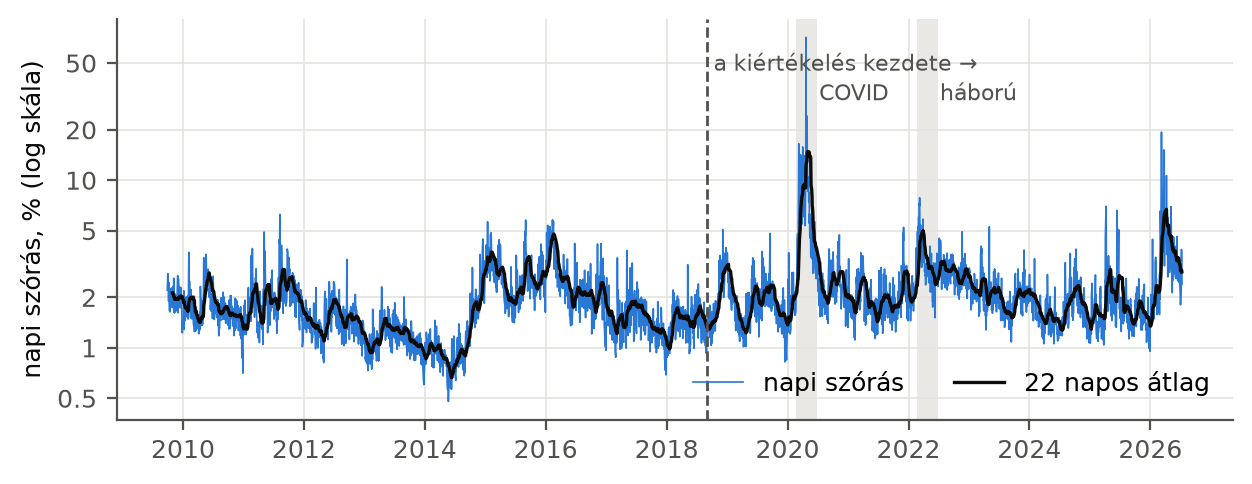

f2_main_effects.png


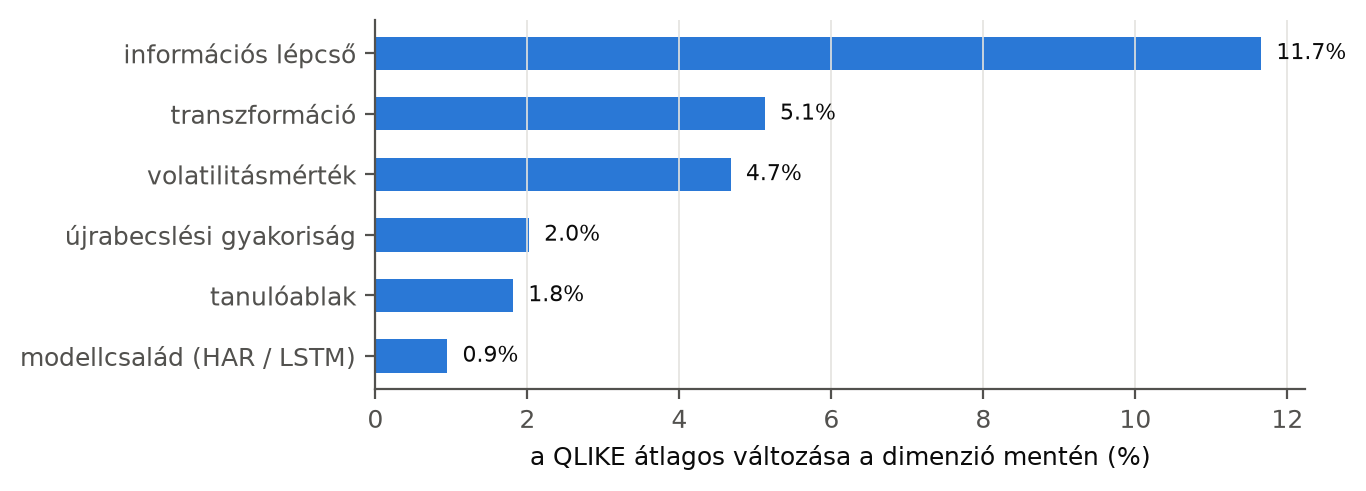

f3_measures_by_year.png


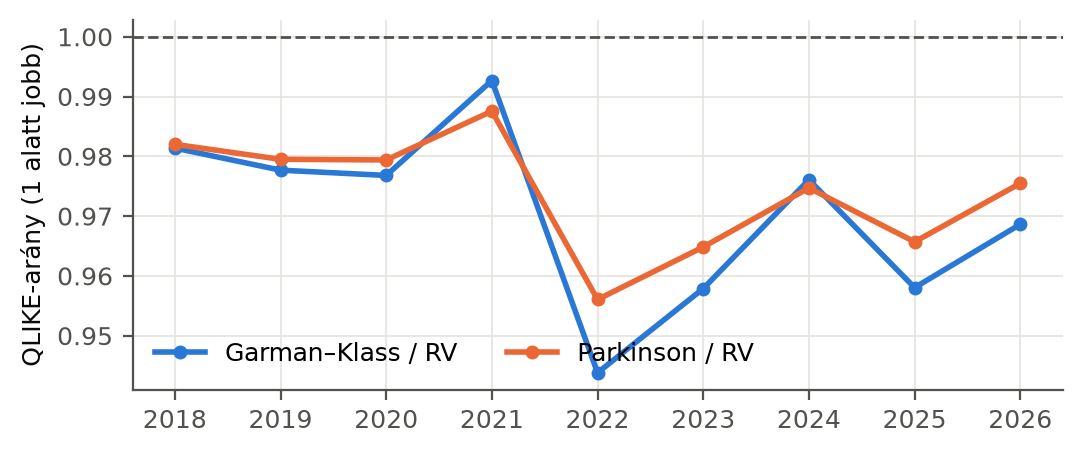

f4_levels_families.png


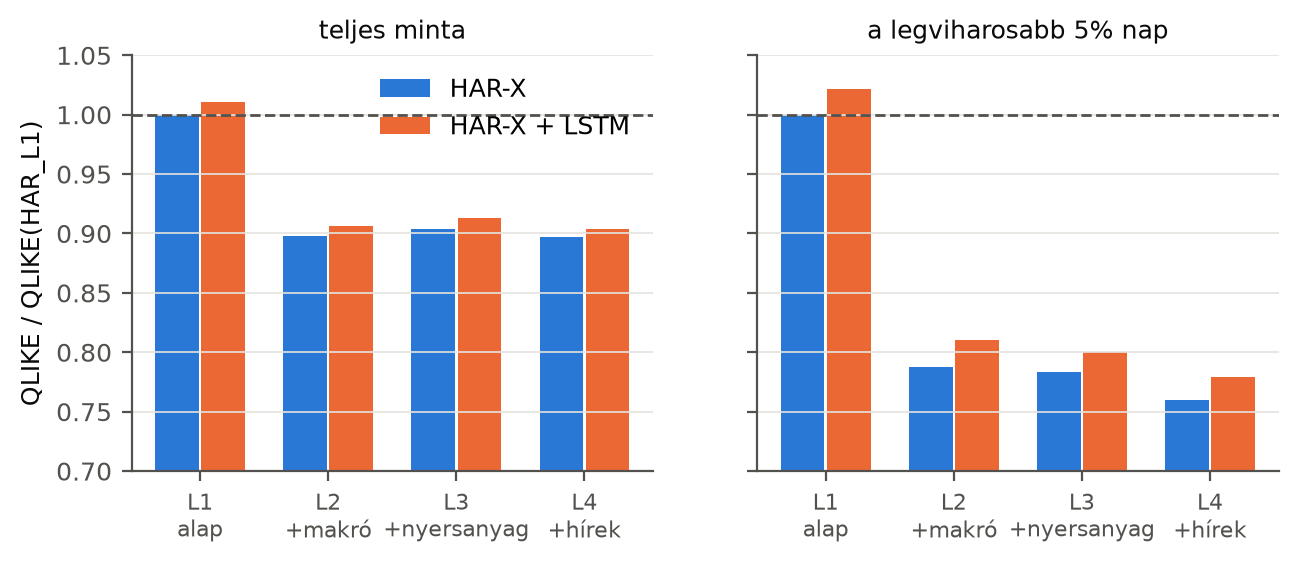

f5_covid.png


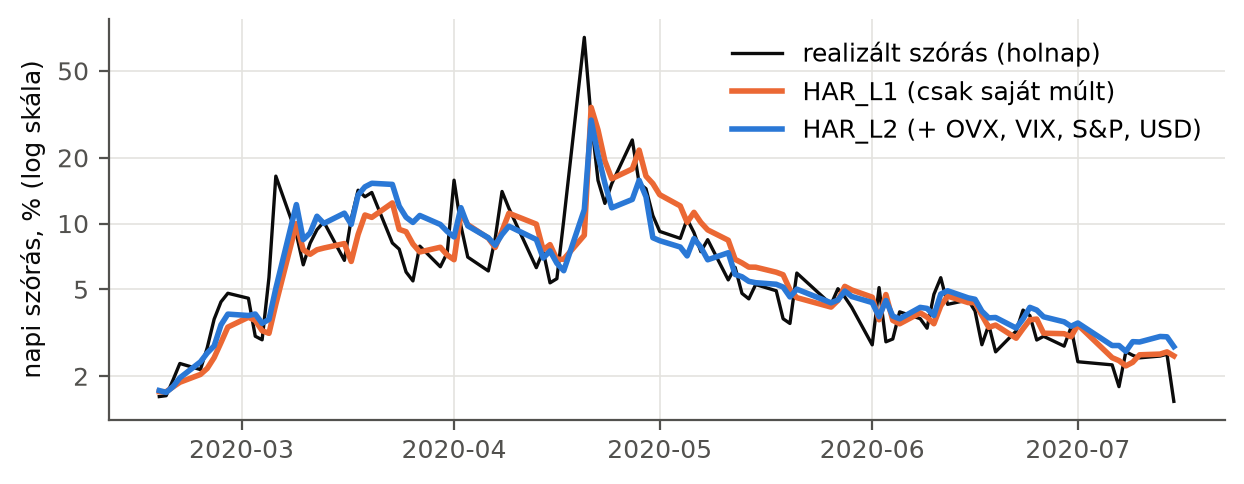

In [8]:
from IPython.display import Image, display
for p in sorted(FIGURES.glob("*.png")):
    print(p.name)
    display(Image(filename=str(p), width=900))

## 5. Automatikus tesztek

A `tests/` mappa 21 tesztje ellenőrzi a képleteket, az időzítést (nincs jövőbeli adat) és a reprodukálhatóságot.

In [9]:
import subprocess
eredmeny = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", str(ROOT / "tests")], capture_output=True, text=True, cwd=ROOT)
print(eredmeny.stdout[-1500:])

.....................                                                    [100%]
21 passed in 13.03s

